<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-021-xy-without-labels.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 021 <br>
<hr/>

# Lab 021 — The 2D XY model without labels

Lab 019 showed that two unsupervised methods, principal component analysis (PCA) and autoencoder (AE) anomaly detection, locate the
critical temperature of the 2D Ising model from raw snapshots, and Lab 020 used the same tools to map the phase diagram of a frustrated
magnet. In both models the phases differ by a **local order parameter** that is linear in the spins, and the methods found exactly that
order parameter. The two-dimensional (2D) XY model of Lab 030 is the test case in which this picture breaks down. Its spins are planar unit
vectors, the magnetisation vanishes at every temperature $T>0$ in the thermodynamic limit (Mermin–Wagner), and the transition at
$T_{\rm BKT}$ is the Berezinskii–Kosterlitz–Thouless (BKT) transition: the unbinding of vortex–antivortex pairs, seen in the
thermodynamics as a universal jump of the spin stiffness and not as the onset of any local order. The spin stiffness, or
**helicity modulus** $\Upsilon$, is the free-energy cost of twisting the angles across the sample, $F(\Delta)-F(0)=\frac{\Upsilon}{2}\Delta^2$ for
a total twist $\Delta$ (defined precisely in Section 1): it is positive in the low-temperature phase, where the spins resist a twist as a
superfluid resists a phase gradient, and zero in the high-temperature phase. A **vortex** is a plaquette of the lattice around which the
angle winds once by $2\pi$; its **winding number** $w=\pm1$ (defined in Section 2) counts the windings with their sense of rotation.

We follow the protocol of the lecture: the physics is known first, then the unsupervised methods run on the snapshots without any label,
and finally every number they produce is compared with the known reference values. Lab 030 gives us those reference values. The
high-precision Monte Carlo result is $T_{\rm BKT}=1/1.1199=0.8929$ (Hasenbusch 2005); the crossings of the helicity modulus with the line
$2T/\pi$ on our own lattices lie at $T^*(L)=0.936,\,0.921,\,0.917$ for $L=16,32,48$ and extrapolate to $0.897\pm0.003$; the specific
heat has a smooth maximum well above the transition, at $T\approx1.06$–$1.12$. A detector that "finds the transition" can therefore land
on three different temperatures, and Lab 030 already warned which ones are tempting: the drop of the finite-lattice magnetisation, and the
smooth proliferation of vortices.

A second theme of this notebook is the **input representation**. A snapshot can be presented to an algorithm as the raw spin vectors
$(\cos\theta_i,\sin\theta_i)$, as the map of vortices (the winding number of every plaquette), or as the map of nearest-neighbour bond
energies $\cos(\theta_i-\theta_j)$. Beach, Golubeva and Melko (2018) showed that a supervised convolutional network fed with raw spins
classifies the XY phases by learning the magnetisation, and that vortex input changes what is learned. We ask the same question for the
unsupervised methods. Section 1 recomputes the reference values from the data set of Lab 030, Section 2 builds the three representations,
Section 3 applies PCA, Section 4 trains convolutional autoencoders on each representation and tests whether network size or a finite-size extrapolation changes the picture, and Section 5 compares every estimate with
$T_{\rm BKT}$, with the stiffness crossings and with the specific-heat maximum.

> The notebook runs on the CPU. It needs the data sets for $L=16,32,48$ generated by Lab 030, so run Lab 030 first.
> On 8 CPU cores the whole notebook takes about ten minutes.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # the whole notebook runs on the CPU
os.environ["CUDA_VISIBLE_DEVICES"] = ""      # and never touches a GPU
import time, json

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA as SklearnPCA

import jax
import jax.numpy as jnp
import optax
from flax import nnx

print("JAX", jax.__version__, "| devices:", jax.devices())
T_START = time.time()

UJBlue, UJNavy, DSOrange, UJGray, Green = "#005CA7", "#002B5C", "#D35A05", "#5A6270", "#2E8B57"
L_COLORS = {16: "#7FB2DC", 32: UJBlue, 48: UJNavy}             # one colour per lattice size, light = small (as in Lab 030)
# Every figure of this notebook is used on a lecture slide. It is drawn at its physical size on the slide
# (text width 5.5 in, usable height about 2.6 in: a figure next to text is 3.2 in wide, a full-width one 5.5 in),
# so the fonts below (10-11 pt) appear on the slide at the size of the slide text.
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10.5,
                     "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
                     "legend.fontsize": 10, "lines.linewidth": 1.6, "lines.markersize": 4})
FIG, DATA = "../beamer/figures", "data"
os.makedirs(FIG, exist_ok=True)
NUMBERS = {}                                                    # numbers quoted on the slides
savefig = lambda fig, name: fig.savefig(f"{FIG}/{name}", dpi=200, bbox_inches="tight")

TWO_PI = 2 * np.pi
T_BKT_LIT = 1.0 / 1.1199                                        # Hasenbusch, J. Phys. A 38, 5869 (2005)
L_LIST = [16, 32, 48]
DS = {L: dict(np.load(f"{DATA}/xy_L{L}.npz")) for L in L_LIST}
T_GRID = DS[16]["T"]
nT = len(T_GRID)
for L in L_LIST:
    d = DS[L]
    assert d["theta"].shape == (nT, 192, L, L) and np.allclose(d["T"], T_GRID)
    print(f"L = {L}: theta {d['theta'].shape}, {int(d['n_chains'])} chains x {int(d['n_store'])} snapshots per temperature")
print("temperatures:", T_GRID)

JAX 0.11.0 | devices: [CpuDevice(id=0)]
L = 16: theta (19, 192, 16, 16), 24 chains x 8 snapshots per temperature
L = 32: theta (19, 192, 32, 32), 24 chains x 8 snapshots per temperature
L = 48: theta (19, 192, 48, 48), 24 chains x 8 snapshots per temperature
temperatures: [0.6  0.65 0.7  0.75 0.8  0.85 0.9  0.95 1.   1.05 1.1  1.15 1.2  1.25
 1.3  1.35 1.4  1.45 1.5 ]


<hr/>
## 1. Reference values from the data set

Every file contains, besides the snapshots `theta` of shape `(19, 192, L, L)`, the per-chain averages `chain_moments` of shape
`(19, 24, 9)` accumulated over all 1000 measurement steps of each Monte Carlo chain. From them we recompute, exactly as in Lab 030, the
quantities against which the unsupervised results will be judged: the mean modulus of the magnetisation $\langle|\boldsymbol m|\rangle$
with $\boldsymbol m=\frac1N\sum_i(\cos\theta_i,\sin\theta_i)$ and $N=L^2$, the energy per spin $u=\langle H\rangle/N$, the specific heat
$c=(\langle H^2\rangle-\langle H\rangle^2)/(NT^2)$, the vortex density $\langle n_v\rangle$ (plaquettes with non-zero winding number per
site), and the helicity modulus (spin stiffness), the resistance of the spin system to a twist of the angles,
$$
\Upsilon=\frac{1}{2N}\Big[\langle C_x+C_y\rangle-\beta\,\langle S_x^2+S_y^2\rangle\Big],\qquad
C_\mu=\sum_r\cos\Delta^\mu_r,\quad S_\mu=\sum_r\sin\Delta^\mu_r,\quad \Delta^\mu_r=\theta_{r+\hat\mu}-\theta_r ,
$$
with $J=1$ and $\beta=1/T$.

Each of these quantities has two forms, and it is worth keeping them apart. The definition is an average over the Boltzmann distribution,
$\langle O\rangle=Z^{-1}\int d\boldsymbol\theta\,O(\boldsymbol\theta)\,e^{-\beta H(\boldsymbol\theta)}$ with the partition function
$Z=\int d\boldsymbol\theta\,e^{-\beta H}$; the energy and the specific heat are derivatives of $\ln Z$,
$u=-\frac1N\partial_\beta\ln Z$ and $c=\frac{\beta^2}{N}\partial_\beta^2\ln Z=\frac{\beta^2}{N}(\langle H^2\rangle-\langle H\rangle^2)$, and the helicity
modulus is the curvature of the free energy $F(\alpha)=-T\ln Z(\alpha)$ when every horizontal bond angle is shifted by a twist $\alpha$,
$\Upsilon=\frac1N\partial_\alpha^2F|_{\alpha=0}$, which gives the expression above (with $\langle S_\mu\rangle=0$ by symmetry, and averaged over
the two directions). The estimator is what the code computes from the $n=24\times1000$ Monte Carlo measurements per temperature: every
$\langle\cdot\rangle$ is replaced by the sample mean $\overline{x}=\frac1n\sum_kx_k$, pooled over all chains and steps, so that
$u=\overline E/N$, $c=\beta^2(\overline{E^2}-\overline E^{\,2})/N$ (a variance that divides by $n$),
$\Upsilon=[\overline{C_x+C_y}-\beta\,\overline{S_x^2+S_y^2}]/(2N)$, $\langle|\boldsymbol m|\rangle\to\overline{|\boldsymbol m|}$ and
$\langle n_v\rangle\to\overline{n_v}$. The quantities of the later sections follow the same pattern: the PCA coordinate is
$\overline{|\mathbf w|}/\sqrt N$ (defined in Section 3) over the 192 snapshots of a temperature, and the anomaly score $\bar\varepsilon(T)$ is the sample mean of the
reconstruction error over the 96 held-out snapshots (and over the two training seeds).

Two reference temperatures follow for each $L$: the crossing $T^*(L)$ of $\Upsilon_L(T)$ with the line
$2T/\pi$ (the finite-size image of the universal jump, approaching $T_{\rm BKT}$ from above as $L$ grows), and the position of the
specific-heat maximum, from a parabola through the five grid points around it. Both are computed with the same code as in Lab 030, so
the printed values must agree with the numbers quoted in the introduction.

In [2]:
MOM = [str(s) for s in DS[16]["moment_names"]]                 # E, E2, C, S2, absm, m2, m4, nv, acc

def reference(d):
    # pooled averages over the 24 chains of every temperature -> dict of arrays of shape (nT,)
    L = int(d["L"]); N = L * L; beta = 1.0 / T_GRID
    v = d["chain_moments"].mean(1)                              # (nT, 9)
    col = lambda name: v[:, MOM.index(name)]
    return dict(absm=col("absm"), m2=col("m2"), u=col("E") / N, nv=col("nv"),
                c=beta**2 * (col("E2") - col("E") ** 2) / N,
                ups=(col("C") - beta * col("S2")) / (2 * N))

def crossing(T, ups):
    # temperature where ups(T) - 2T/pi changes sign, linear interpolation between grid points
    f = ups - 2 * T / np.pi
    i = np.nonzero((f[:-1] > 0) & (f[1:] <= 0))[0][0]
    return T[i] - f[i] * (T[i + 1] - T[i]) / (f[i + 1] - f[i])

def peak_parabola(T, y):
    # position of the maximum of y(T) from a parabola through the five grid points around the largest value
    i = int(np.argmax(y)); p = np.polyfit(T[i - 2:i + 3], y[i - 2:i + 3], 2)
    return -p[1] / (2 * p[0])

REF = {L: reference(DS[L]) for L in L_LIST}
T_UPS = {L: crossing(T_GRID, REF[L]["ups"]) for L in L_LIST}
T_CMAX = {L: peak_parabola(T_GRID, REF[L]["c"]) for L in L_LIST}
print(f"literature: T_BKT = {T_BKT_LIT:.4f}")
for L in L_LIST:
    print(f"L = {L}:  stiffness crossing T*(L) = {T_UPS[L]:.4f}   specific-heat maximum at T = {T_CMAX[L]:.3f}")
NUMBERS.update(T_BKT_literature=round(T_BKT_LIT, 4), **{f"T_ups_L{L}": round(float(T_UPS[L]), 4) for L in L_LIST},
               **{f"T_cmax_L{L}": round(float(T_CMAX[L]), 3) for L in L_LIST})

literature: T_BKT = 0.8929
L = 16:  stiffness crossing T*(L) = 0.9357   specific-heat maximum at T = 1.117
L = 32:  stiffness crossing T*(L) = 0.9211   specific-heat maximum at T = 1.067
L = 48:  stiffness crossing T*(L) = 0.9170   specific-heat maximum at T = 1.060


<hr/>
## 2. Three representations of a snapshot

A snapshot is the array of angles $\theta_r\in[0,2\pi)$ on the $L\times L$ torus. The angle itself is a poor input for a neural network:
$\theta=0.01$ and $\theta=6.27$ describe almost the same spin but are far apart as numbers. We therefore never feed angles directly, and
use three representations, each an array of shape `(..., L, L, channels)` with the channel axis last, as Flax convolutions expect.

The **spin vectors** keep all information, two channels per site,
$$
\boldsymbol s_r=(\cos\theta_r,\ \sin\theta_r)\qquad\text{shape }(\dots,L,L,2).
$$
Under the global rotation $\theta_r\to\theta_r+\alpha$, the symmetry of $H=-J\sum_{\langle ij\rangle}\cos(\theta_i-\theta_j)$, every
$\boldsymbol s_r$ is multiplied by the same $2\times2$ rotation matrix: the representation is not invariant, and two snapshots that differ
only by a rotation are physically identical but numerically different.

The **vortex map** is the winding number of every plaquette (Lab 030, Section 4.1),
$$
w_r=\frac{1}{2\pi}\Big([\theta_{r+\hat x}-\theta_r]+[\theta_{r+\hat x+\hat y}-\theta_{r+\hat x}]+[\theta_{r+\hat y}-\theta_{r+\hat x+\hat y}]
+[\theta_r-\theta_{r+\hat y}]\Big)\in\{-1,0,1\},\qquad\text{shape }(\dots,L,L,1),
$$
where $[x]$ is $x$ mapped to $[-\pi,\pi)$ (the sum of four brackets lies in $[-4\pi,4\pi)$, and $w_r=-2$ would need all four to equal $-\pi$ exactly). It depends only on angle differences, so it is invariant under global rotations, and it
contains exactly the topological defects that drive the transition. It discards the spin waves.

The **bond-energy map** keeps the two bonds leaving every site,
$$
b_r=\big(\cos(\theta_{r+\hat x}-\theta_r),\ \cos(\theta_{r+\hat y}-\theta_r)\big)\qquad\text{shape }(\dots,L,L,2),
$$
so that $H=-J\sum_r(b_r^x+b_r^y)$. It is rotation invariant and is the local energy density of the snapshot.

The cell below implements the three maps and checks their symmetry properties on 16 snapshots of the $L=32$ data set: the vortex and bond
maps must not change under a global rotation, the spin vectors must rotate rigidly, and the winding numbers of every snapshot must sum to
zero on the torus (every bond enters two plaquettes with opposite signs). It also compares the vortex density counted in the stored
snapshots with the density $\langle n_v\rangle$ that Lab 030 accumulated over all Monte Carlo steps.

In [3]:
def wrap(a):
    # map angles to [-pi, pi)
    return (a + jnp.pi) % TWO_PI - jnp.pi

def to_spins(theta):
    # (..., L, L) -> (..., L, L, 2): channels cos(theta), sin(theta)
    return jnp.stack([jnp.cos(theta), jnp.sin(theta)], -1)

def to_vortices(theta):
    # (..., L, L) -> (..., L, L, 1): winding number of the plaquette with lower-left corner r, counter-clockwise
    t01 = jnp.roll(theta, -1, -1); t11 = jnp.roll(t01, -1, -2); t10 = jnp.roll(theta, -1, -2)
    circ = wrap(t01 - theta) + wrap(t11 - t01) + wrap(t10 - t11) + wrap(theta - t10)
    return jnp.round(circ / TWO_PI)[..., None]

def to_bonds(theta):
    # (..., L, L) -> (..., L, L, 2): cos of the angle difference on the bond to the right (x) and to the upper (y) neighbour
    return jnp.stack([jnp.cos(jnp.roll(theta, -1, -1) - theta), jnp.cos(jnp.roll(theta, -1, -2) - theta)], -1)

REPS = {"spins": to_spins, "vortices": to_vortices, "bonds": to_bonds}
CHANNELS = {"spins": 2, "vortices": 1, "bonds": 2}

th = jnp.asarray(DS[32]["theta"][8, :16])                       # 16 snapshots at T = 1.00, shape (16, 32, 32)
alpha = 1.234
R = jnp.array([[np.cos(alpha), -np.sin(alpha)], [np.sin(alpha), np.cos(alpha)]])
assert jnp.allclose(to_spins(th + alpha), to_spins(th) @ R.T, atol=1e-5)           # spins rotate rigidly
assert jnp.array_equal(to_vortices(th + alpha), to_vortices(th))                   # vortex map invariant
assert jnp.allclose(to_bonds(th + alpha), to_bonds(th), atol=1e-5)                 # bond map invariant
assert jnp.all(to_vortices(th).sum((1, 2, 3)) == 0)                                # total winding zero on the torus
energy = -(to_bonds(th).sum((1, 2, 3))) / 32**2
print("shapes:", {k: f(th).shape for k, f in REPS.items()})
print(f"energy per spin of the 16 snapshots from the bond map: {float(energy.mean()):+.4f}   "
      f"chain average u(T=1.00) = {REF[32]['u'][8]:+.4f}")
for L in L_LIST:
    w = np.asarray(to_vortices(jnp.asarray(DS[L]["theta"])))
    print(f"L = {L}: vortex density in the stored snapshots at T = 0.90 / 1.50: {(w[6] != 0).mean():.4f} / {(w[-1] != 0).mean():.4f}"
          f"   (Lab 030, all MC steps: {REF[L]['nv'][6]:.4f} / {REF[L]['nv'][-1]:.4f})")

shapes: {'spins': (16, 32, 32, 2), 'vortices': (16, 32, 32, 1), 'bonds': (16, 32, 32, 2)}
energy per spin of the 16 snapshots from the bond map: -1.3174   chain average u(T=1.00) = -1.3250


L = 16: vortex density in the stored snapshots at T = 0.90 / 1.50: 0.0086 / 0.1372   (Lab 030, all MC steps: 0.0083 / 0.1372)


L = 32: vortex density in the stored snapshots at T = 0.90 / 1.50: 0.0087 / 0.1388   (Lab 030, all MC steps: 0.0091 / 0.1375)


L = 48: vortex density in the stored snapshots at T = 0.90 / 1.50: 0.0091 / 0.1371   (Lab 030, all MC steps: 0.0090 / 0.1372)


The figure shows the three representations of one $L=32$ snapshot below $T_{\rm BKT}$ ($T=0.80$) and one in the high-temperature phase
($T=1.20$). At $T=0.80$ the angle varies smoothly over large regions (spin waves), the vortex map is almost empty, and the bond energies
are close to $1$ everywhere. At $T=1.20$ the angle field is broken into small domains, vortices (red, $w=+1$) and antivortices (blue, $w=-1$) are
numerous, and the bond map is noisy. Note that the three maps of one snapshot look very different: whatever an algorithm learns depends
on which of them we show it.

T = 0.80: 0 vortices, 0 antivortices in the shown snapshot
T = 1.20: 33 vortices, 33 antivortices in the shown snapshot


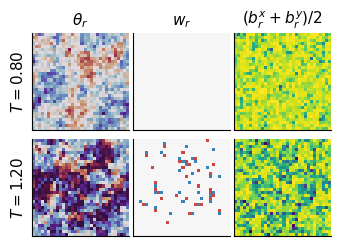

In [4]:
L = 32
fig, axes = plt.subplots(2, 3, figsize=(3.3, 2.45))
for row, T in enumerate([0.80, 1.20]):
    i = int(np.argmin(abs(T_GRID - T)))
    th = jnp.asarray(DS[L]["theta"][i, 0])
    w = np.asarray(to_vortices(th))[..., 0]; b = np.asarray(to_bonds(th)).mean(-1)
    panels = [(np.asarray(th), "twilight", 0, TWO_PI, r"$\theta_r$"), (w, "RdBu_r", -1.5, 1.5, r"$w_r$"),
              (b, "viridis", -1, 1, r"$(b^x_r+b^y_r)/2$")]
    for ax, (img, cmap, lo, hi, title) in zip(axes[row], panels):
        ax.imshow(img, cmap=cmap, vmin=lo, vmax=hi, origin="lower")
        ax.set_xticks([]); ax.set_yticks([])
        if row == 0: ax.set_title(title)
    axes[row, 0].set_ylabel(f"$T={T_GRID[i]:.2f}$")
    print(f"T = {T_GRID[i]:.2f}: {int((w > 0).sum())} vortices, {int((w < 0).sum())} antivortices in the shown snapshot")
fig.tight_layout(pad=0.3); savefig(fig, "gen_xy_ml_representations.png"); plt.show()

<hr/>
## 3. Principal component analysis

### 3.1 Spectra of the three representations

PCA (Lab 016) receives a data matrix $X$ of shape `(n, D)`, one flattened snapshot per row, subtracts the mean row $\bar{\boldsymbol x}$,
and diagonalises the covariance matrix through the singular value decomposition $X-\bar{\boldsymbol x}=USV^{\mathsf T}$, with singular
values $s_l$ on the diagonal of $S$. The rows $\boldsymbol\lambda_l^{\mathsf T}$ of $V^{\mathsf T}$ are the principal directions, the variance
along $\boldsymbol\lambda_l$ is the eigenvalue $\sigma_l^2=s_l^2/n$ of the covariance matrix, the fraction of the variance carried by
direction $l$ is $\sigma_l^2/\sum_{l'}\sigma_{l'}^2$, and the projections $w^{(l)}=\boldsymbol\lambda_l^{\mathsf T}(\boldsymbol x-\bar{\boldsymbol x})$
are the coordinates of a snapshot (the superscript in parentheses distinguishes them from the winding numbers $w_r$ of the vortex map). We pool all $19\times192=3648$ snapshots of one lattice size, with no temperature attached. For the spin
vectors $D=2N$: the first $N$ entries of a row are the $\cos\theta_r$, the next $N$ the $\sin\theta_r$; for the bond map also $D=2N$, for
the vortex map $D=N$.

One detail matters before the first computation. The Monte Carlo chains of Lab 030 started from the ordered state $\theta_r=0$, and at low
temperature a large lattice turns its global direction only slowly, so the stored snapshots of $L=48$ at $T=0.60$ still point mostly near
$\theta=0$. The mean row $\bar{\boldsymbol x}$ would then contain a spurious magnetisation along $x$. The physics does not prefer any
direction, so we rotate every snapshot by its own random angle $\alpha\in[0,2\pi)$ before the analysis: this uses the symmetry of $H$
and costs nothing. The rotation does not change the vortex and bond maps.

The PCA implementation in JAX is a few lines; we check it against `sklearn.decomposition.PCA` on the spin vectors of $L=32$. The
explained-variance fractions must agree, and so must the principal directions up to sign. The first two directions turn out to carry
equal variance (we shall see why), so any rotation of the two inside their common plane is an equally valid answer; we compare the
plane instead of the individual vectors, through the cosines of the principal angles between the two planes (the singular values of
$V_{\rm JAX}V_{\rm sklearn}^{\mathsf T}$ restricted to the two directions), which are $1$ for identical planes.

In [5]:
@jax.jit
def pca_fit(X):
    # X: (n, D) data matrix -> mean (D,), explained-variance fractions (min(n, D),), principal directions as rows (min(n, D), D)
    mu = X.mean(0)
    _, sv, Vt = jnp.linalg.svd(X - mu, full_matrices=False)
    return mu, sv**2 / jnp.sum(sv**2), Vt

def design_matrix(L, rep, seed=0):
    # all snapshots of size L, each rotated by a random global angle, in representation rep -> (19 * 192, D), channel-major
    theta = jnp.asarray(DS[L]["theta"].reshape(-1, L, L))
    alpha = jax.random.uniform(jax.random.PRNGKey(seed), (theta.shape[0], 1, 1), maxval=TWO_PI)
    x = REPS[rep](theta + alpha)                                 # (n, L, L, c)
    return jnp.moveaxis(x, -1, 1).reshape(theta.shape[0], -1)    # (n, c * L * L)

X32 = design_matrix(32, "spins")
mu32, var32, Vt32 = pca_fit(X32)
sk = SklearnPCA(n_components=10, svd_solver="full").fit(np.asarray(X32))
print("explained variance, JAX    :", np.round(np.asarray(var32[:6]), 5))
print("explained variance, sklearn:", np.round(sk.explained_variance_ratio_[:6], 5))
assert np.allclose(np.asarray(var32[:10]), sk.explained_variance_ratio_, atol=1e-5)
cos_angles = np.linalg.svd(np.asarray(Vt32[:2]) @ sk.components_[:2].T, compute_uv=False)
print("cosines of the principal angles between the leading planes (JAX vs sklearn):", np.round(cos_angles, 6))
assert np.all(cos_angles > 1 - 1e-4)
k3 = abs(float(np.asarray(Vt32[2]) @ sk.components_[2]))
print(f"|lambda_3(JAX) . lambda_3(sklearn)| = {k3:.6f}   (1 means equal up to sign; below 1 the third direction is degenerate with the fourth)")

explained variance, JAX    : [0.13376 0.13161 0.00951 0.00916 0.00884 0.0087 ]
explained variance, sklearn: [0.13376 0.13161 0.00951 0.00916 0.00884 0.0087 ]
cosines of the principal angles between the leading planes (JAX vs sklearn): [1.       0.999999]
|lambda_3(JAX) . lambda_3(sklearn)| = 1.000000   (1 means equal up to sign; below 1 the third direction is degenerate with the fourth)


With the implementation checked, we compute the spectrum of each representation for $L=32$, and the overlap of the leading directions with
the two **uniform** patterns of the spin vectors,
$$
\boldsymbol u_c=\tfrac{1}{\sqrt N}(\underbrace{1,\dots,1}_{\cos\ \text{part}},\underbrace{0,\dots,0}_{\sin\ \text{part}}),\qquad
\boldsymbol u_s=\tfrac{1}{\sqrt N}(0,\dots,0,1,\dots,1),
$$
measured as the length of the projection of $\boldsymbol u_c$ and $\boldsymbol u_s$ onto the plane of $\boldsymbol\lambda_1,\boldsymbol\lambda_2$
(1 if the plane contains the vector). For the bond map the analogous check is the overlap of $\boldsymbol\lambda_1$ with the uniform vector
$(1,\dots,1)/\sqrt{2N}$, whose projection is proportional to the energy of the snapshot.

spins    : explained variance of the first 6 directions (%): [13.38 13.16  0.95  0.92  0.88  0.87]


vortices : explained variance of the first 6 directions (%): [0.34 0.34 0.33 0.33 0.33 0.33]


bonds    : explained variance of the first 6 directions (%): [9.28 0.19 0.18 0.18 0.18 0.18]
spins: projection of u_c, u_s onto the plane (lambda_1, lambda_2): 0.9995, 0.9995
bonds: overlap of lambda_1 with the uniform vector: 0.9986


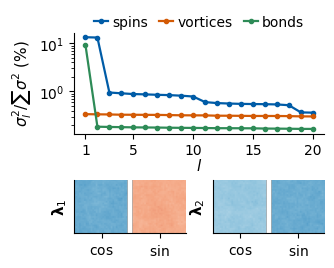

In [6]:
SPEC = {}
for rep in REPS:
    X = X32 if rep == "spins" else design_matrix(32, rep)
    mu, var, Vt = pca_fit(X)
    SPEC[rep] = (np.asarray(var), np.asarray(Vt[:4]))
    print(f"{rep:9s}: explained variance of the first 6 directions (%):", np.round(100 * np.asarray(var[:6]), 2))
N32 = 32 * 32
u_c = np.r_[np.ones(N32), np.zeros(N32)] / np.sqrt(N32); u_s = np.r_[np.zeros(N32), np.ones(N32)] / np.sqrt(N32)
P = SPEC["spins"][1][:2]
ov = [float(np.linalg.norm(P @ u)) for u in (u_c, u_s)]
ov_b = abs(float(SPEC["bonds"][1][0] @ np.ones(2 * N32) / np.sqrt(2 * N32)))
print(f"spins: projection of u_c, u_s onto the plane (lambda_1, lambda_2): {ov[0]:.4f}, {ov[1]:.4f}")
print(f"bonds: overlap of lambda_1 with the uniform vector: {ov_b:.4f}")
NUMBERS.update(pca_var_spins_L32=[round(100 * float(v), 2) for v in SPEC["spins"][0][:4]],
               pca_var_bonds_L32=[round(100 * float(v), 2) for v in SPEC["bonds"][0][:4]],
               pca_var_vortices_L32=[round(100 * float(v), 3) for v in SPEC["vortices"][0][:4]],
               pca_overlap_uniform=round(min(ov), 4), pca_overlap_bonds=round(ov_b, 4))

fig = plt.figure(figsize=(3.2, 2.55))
gs = fig.add_gridspec(2, 2, height_ratios=[1.25, 1])
a0 = fig.add_subplot(gs[0, :])
for rep, col, lab in zip(REPS, [UJBlue, DSOrange, Green], ["spins", "vortices", "bonds"]):
    a0.plot(np.arange(1, 21), 100 * SPEC[rep][0][:20], "o-", ms=3, color=col, label=lab)
a0.set_yscale("log"); a0.set_xlabel("$l$", labelpad=0); a0.set_ylabel(r"$\sigma_l^2/\sum\sigma^2$ (%)")
a0.set_xticks([1, 5, 10, 15, 20]); a0.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.3),
                                             handlelength=1.0, columnspacing=0.8, handletextpad=0.3)
for j, k in enumerate([0, 1]):
    a = fig.add_subplot(gs[1, j])
    v = SPEC["spins"][1][k].reshape(2, 32, 32) * np.sqrt(N32)
    a.imshow(np.concatenate([v[0], np.full((32, 3), np.nan), v[1]], 1), cmap="RdBu_r", vmin=-1.6, vmax=1.6, origin="lower")
    a.set_xticks([16, 51]); a.set_xticklabels([r"$\cos$", r"$\sin$"]); a.set_yticks([])
    a.set_ylabel(rf"$\boldsymbol{{\lambda}}_{k + 1}$")
fig.tight_layout(pad=0.2, h_pad=0.4); savefig(fig, "gen_xy_ml_pca_spectra.png"); plt.show()

The three spectra are very different. For the **spin vectors** two directions stand far above the rest and carry equal variance, and the
images show what they are: the $\cos$ part and the $\sin$ part are each uniform, i.e. $\boldsymbol\lambda_1,\boldsymbol\lambda_2$ span the plane of
$\boldsymbol u_c,\boldsymbol u_s$ (projections printed above, close to 1). The equal variance is the rotation symmetry: after the random
rotations, $m_x$ and $m_y$ fluctuate identically, and PCA has found the two components of the magnetisation as an $O(2)$ pair. The next
directions are the long-wavelength spin waves, again in degenerate groups. For the **bond map** one direction dominates and is the uniform
pattern, i.e. the energy of the snapshot. For the **vortex map** the spectrum is flat: there is no linear combination of the winding
numbers that varies much more than any other. The uniform combination, the total vorticity, is exactly zero on the torus, and the physics
of the transition, whether vortices are bound in pairs, is a statement about correlations between defects, not about a linear pattern.
PCA has nothing to find there.

### 3.2 The magnetisation pair and its finite-size drift

The projections onto the leading plane give a two-component coordinate $\mathbf w=(w^{(1)},w^{(2)})$ per snapshot. Because the plane is spanned by
$\boldsymbol u_c$ and $\boldsymbol u_s$, and $\boldsymbol u_c\cdot\boldsymbol x=\frac{1}{\sqrt N}\sum_r\cos\theta_r=\sqrt N\,m_x$,
$$
\frac{|\mathbf w|}{\sqrt N}=\frac{\sqrt{(w^{(1)})^2+(w^{(2)})^2}}{\sqrt N}\simeq|\boldsymbol m| ,
$$
so the PCA order parameter is the modulus of the finite-lattice magnetisation. We compute it for all three sizes and locate the
temperature where it falls fastest, $T_{\rm PCA}(L)$: the maximum of $-d\langle|\mathbf w|\rangle/dT$, estimated by central differences on the
grid and refined with a parabola through the three largest slopes. The error bar comes from a bootstrap over the 24 independent Monte
Carlo chains (we resample chains with replacement, 200 times, and take the standard deviation of the estimate).

Lab 030 tells us what to expect. Below $T_{\rm BKT}$ the magnetisation decays as $\langle|\boldsymbol m|\rangle\propto L^{-\eta(T)/2}$ with
$\eta(T)=T/(2\pi\Upsilon)$, so it is a power law in $L$ with a small exponent, never an order parameter; above $T_{\rm BKT}$ it decays
faster, as $\xi/L$ once the correlation length $\xi$ is smaller than $L$. The lower panel of the figure tests this with the effective exponent
$x_{\rm eff}(T)$ from a fit $\langle|\mathbf w|\rangle/\sqrt N\propto L^{-x_{\rm eff}}$ to the three sizes, compared with $\eta/2=T/(4\pi\Upsilon_{48})$
computed from the measured helicity modulus of $L=48$.

L = 16: variance fraction of lambda_1, lambda_2 = 34.7% ,  max |<|w|>/sqrt(N) - <|m|>| over T = 0.0008 ,  steepest fall at T_PCA = 1.129 +- 0.015


L = 32: variance fraction of lambda_1, lambda_2 = 26.5% ,  max |<|w|>/sqrt(N) - <|m|>| over T = 0.0011 ,  steepest fall at T_PCA = 1.062 +- 0.006


L = 48: variance fraction of lambda_1, lambda_2 = 23.3% ,  max |<|w|>/sqrt(N) - <|m|>| over T = 0.0021 ,  steepest fall at T_PCA = 1.033 +- 0.006
T = 0.60:  x_eff = 0.064   eta/2 = T/(4 pi Upsilon_48) = 0.058
T = 0.70:  x_eff = 0.065   eta/2 = T/(4 pi Upsilon_48) = 0.072
T = 0.80:  x_eff = 0.085   eta/2 = T/(4 pi Upsilon_48) = 0.089
T = 0.90:  x_eff = 0.128   eta/2 = T/(4 pi Upsilon_48) = 0.117
T = 1.00:  x_eff = 0.247   eta/2 = T/(4 pi Upsilon_48) = 0.248
T = 1.20: x_eff = 0.989;  T = 1.50: x_eff = 0.954


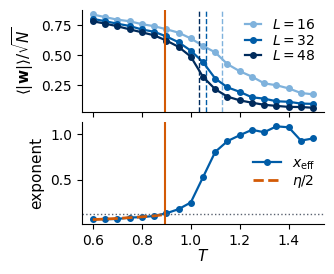

In [7]:
def steepest(T, y, sign=+1):
    # temperature of the steepest rise (sign=+1) or fall (sign=-1) of y(T): central differences, parabola through the 3 largest slopes
    d = sign * np.gradient(y, T)
    i = int(np.clip(np.argmax(d), 1, len(T) - 2))
    p = np.polyfit(T[i - 1:i + 2], d[i - 1:i + 2], 2)
    return float(np.clip(-p[1] / (2 * p[0]), T[i - 1], T[i + 1]))

def bootstrap_steepest(per_sample, chain, sign=+1, n_boot=200, seed=0):
    # per_sample: (nT, n) values for n snapshots per temperature; chain: (n,) chain index of each snapshot.
    # Returns the estimate from all snapshots and its bootstrap standard deviation over chains.
    rng = np.random.default_rng(seed)
    chains = np.unique(chain)
    per_chain = np.stack([per_sample[:, chain == c].mean(1) for c in chains], 1)      # (nT, n_chains)
    boot = [steepest(T_GRID, per_chain[:, rng.integers(0, len(chains), len(chains))].mean(1), sign) for _ in range(n_boot)]
    return steepest(T_GRID, per_chain.mean(1), sign), float(np.std(boot))

ZABS, T_PCA = {}, {}
for L in L_LIST:
    N = L * L
    X = design_matrix(L, "spins")
    mu, var, Vt = pca_fit(X)
    z = (X - mu) @ Vt[:2].T                                                           # (3648, 2)
    ZABS[L] = np.asarray(jnp.linalg.norm(z, axis=1) / np.sqrt(N)).reshape(nT, -1)    # (nT, 192)
    m_abs = np.hypot(np.cos(DS[L]["theta"]).mean((-2, -1)), np.sin(DS[L]["theta"]).mean((-2, -1)))
    T_PCA[L] = bootstrap_steepest(ZABS[L], DS[L]["chain"], sign=-1)
    print(f"L = {L}: variance fraction of lambda_1, lambda_2 = {100 * float(var[0] + var[1]):.1f}% ,  max |<|w|>/sqrt(N) - <|m|>| over T = "
          f"{np.abs(ZABS[L].mean(1) - m_abs.mean(1)).max():.4f} ,  steepest fall at T_PCA = {T_PCA[L][0]:.3f} +- {T_PCA[L][1]:.3f}")
NUMBERS.update(**{f"T_pca_L{L}": round(T_PCA[L][0], 3) for L in L_LIST}, **{f"T_pca_err_L{L}": round(T_PCA[L][1], 3) for L in L_LIST})

zbar = np.stack([ZABS[L].mean(1) for L in L_LIST])                                     # (3, nT)
x_eff = -np.polyfit(np.log(L_LIST), np.log(zbar), 1)[0]                               # (nT,)
eta_half = T_GRID / (4 * np.pi * REF[48]["ups"])
for T in [0.60, 0.70, 0.80, 0.90, 1.00]:
    i = int(np.argmin(abs(T_GRID - T)))
    print(f"T = {T_GRID[i]:.2f}:  x_eff = {x_eff[i]:.3f}   eta/2 = T/(4 pi Upsilon_48) = {eta_half[i]:.3f}")
print(f"T = 1.20: x_eff = {x_eff[12]:.3f};  T = 1.50: x_eff = {x_eff[-1]:.3f}")
NUMBERS.update(x_eff_T060=round(float(x_eff[0]), 3), eta_half_T060=round(float(eta_half[0]), 3),
               x_eff_T090=round(float(x_eff[6]), 3), eta_half_T090=round(float(eta_half[6]), 3),
               x_eff_T150=round(float(x_eff[-1]), 3))

fig, ax = plt.subplots(2, 1, figsize=(3.2, 2.6), sharex=True)
for L in L_LIST:
    ax[0].plot(T_GRID, ZABS[L].mean(1), "o-", color=L_COLORS[L], label=f"$L={L}$")
    ax[0].axvline(T_PCA[L][0], color=L_COLORS[L], ls="--", lw=1)
ax[0].set_ylabel(r"$\langle|\mathbf{w}|\rangle/\sqrt{N}$"); ax[0].legend(frameon=False, borderpad=0.1, labelspacing=0.1, handlelength=1.2)
ax[1].plot(T_GRID, x_eff, "o-", color=UJBlue, label=r"$x_{\rm eff}$")
low = T_GRID <= 0.90 + 1e-9
ax[1].plot(T_GRID[low], eta_half[low], "--", color=DSOrange, lw=2, label=r"$\eta/2$")
ax[1].axhline(1 / 8, color=UJGray, ls=":", lw=1)
ax[1].set_xlabel("$T$", labelpad=0); ax[1].set_ylabel("exponent"); ax[1].legend(frameon=False, loc="center right", borderpad=0.1, labelspacing=0.1)
for a in ax: a.axvline(T_BKT_LIT, color=DSOrange, lw=1.5)
fig.tight_layout(pad=0.2, h_pad=0.3); savefig(fig, "gen_xy_ml_pca_order.png"); plt.show()

The upper panel looks like the plot of an order parameter: $\langle|\mathbf w|\rangle/\sqrt N$ is large at low $T$ and falls around
$T\approx1$. It agrees with $\langle|\boldsymbol m|\rangle$ of the same snapshots to the printed accuracy, so PCA has rediscovered the
magnetisation, as for the Ising model in Lab 019. Two observations show that this is not an order parameter of the XY model. The
low-temperature plateau itself decreases with $L$, and up to $T_{\rm BKT}$ the effective exponent in the lower panel follows the
prediction $\eta/2$ computed from the measured stiffness (for example $0.064$ against $0.058$ at $T=0.60$, $0.128$ against $0.117$ at
$T=0.90$): a power law in $L$, so $\langle|\mathbf w|\rangle\to0$ as $L\to\infty$ at every temperature. And the steepest-fall
temperatures $T_{\rm PCA}(L)$ (dashed lines) lie above $T_{\rm BKT}$ and drift to lower $T$ as $L$ grows. What PCA locates is roughly the
temperature at which the correlation length becomes comparable with the lattice: a finite-size crossover, which approaches $T_{\rm BKT}$
only logarithmically slowly (the same mechanism as for the stiffness crossings, Lab 030 Section 5.3). At high temperature the exponent
approaches $1$, the value for $\xi\ll L$.

This agrees with Hu, Singh and Scalettar (2017), who applied PCA to the XY model, found the magnetisation, and noted that PCA does not
capture the vorticity; Wang and Zhai (2017) applied PCA to frustrated XY models with the same $(\cos\theta,\sin\theta)$ input.

<hr/>
## 4. Autoencoder anomaly detection

### 4.1 A convolutional autoencoder on the torus

The autoencoder (Lab 017) compresses a snapshot $\boldsymbol x$ to a few latent numbers and reconstructs it, $\hat{\boldsymbol x}=
D_\phi(E_\psi(\boldsymbol x))$. Trained only on snapshots from one region of temperature, it reconstructs snapshots that resemble the
training data well and the others badly. The **reconstruction error** of one snapshot,
$$
\varepsilon(\boldsymbol x)=\frac{1}{N\,C}\sum_{r}\sum_{c=1}^{C}\big(x_{r,c}-\hat x_{r,c}\big)^2 ,
$$
with $C$ the number of channels, averaged over the snapshots at temperature $T$, $\bar\varepsilon(T)$, is the anomaly score
(Kottmann, Huembeli, Lewenstein, Acín 2020). The same network is used for all three representations; only the number of input channels
changes. With shapes for a batch of $B$ snapshots of size $L$ (divisible by 4):

| layer | output shape |
|---|---|
| input | $(B, L, L, C)$ |
| convolution $3\times3$, stride 2, periodic padding, 16 filters, ReLU | $(B, L/2, L/2, 16)$ |
| convolution $3\times3$, stride 2, periodic padding, 32 filters, ReLU | $(B, L/4, L/4, 32)$ |
| dense $\to$ latent | $(B, 4)$ |
| dense, ReLU, reshape | $(B, L/4, L/4, 32)$ |
| transposed convolution, stride 2, ReLU | $(B, L/2, L/2, 16)$ |
| transposed convolution, stride 2, linear | $(B, L, L, C)$ |

ReLU is the rectified linear unit, $\mathrm{ReLU}(x)=\max(0,x)$, applied to every entry; a stride of 2 halves each spatial dimension.
The convolutions use periodic ("circular") padding, the boundary condition of the lattice, and the latent space has 4 numbers as in Lab 020.
The output is linear because the targets differ between representations ($\cos\theta,\sin\theta\in[-1,1]$, $w\in\{-1,0,1\}$, $b\in[-1,1]$).

The training protocol uses what we know about the model. Every training batch is rotated by fresh random angles $\alpha$, one per
snapshot, before being converted to the representation: the network sees every global direction and never has to learn a
direction-specific reconstruction (for vortices and bonds the rotation changes nothing). The 24 Monte Carlo chains of each temperature
are split: chains 0–11 provide the training snapshots, chains 12–23 the evaluation snapshots, so that the error at the training
temperatures is measured on snapshots the network has not seen. The training region is the low-temperature end $T\in\{0.60,0.65,0.70\}$,
well below $T_{\rm BKT}$, where spin-wave theory describes the physics (Lab 030); for the raw spins we also train on the high-temperature end
$T\in\{1.40,1.45,1.50\}$. That gives $3\times96=288$ training snapshots; we train with the Adam optimiser (adaptive moment estimation, Lab 017; learning rate $10^{-3}$, batches of 32,
40 epochs). Every low-temperature training is repeated with two random seeds, the high-temperature control is trained once. A temperature estimate $T_{\rm AE}(L)$ is the position of the steepest
rise of $\bar\varepsilon(T)$, with the same estimator and chain bootstrap as for PCA, applied to the seed-averaged curve.

The cell defines the model and checks the shapes for all three sizes and representations.

In [8]:
class ConvAE(nnx.Module):
    def __init__(self, channels, L, latent=4, width=1, *, rngs):
        # width multiplies the number of filters (16 and 32 for width = 1)
        self.l4, f1, f2 = L // 4, 16 * width, 32 * width
        self.f2 = f2
        self.c1 = nnx.Conv(channels, f1, (3, 3), strides=2, padding="CIRCULAR", rngs=rngs)       # L   -> L/2
        self.c2 = nnx.Conv(f1, f2, (3, 3), strides=2, padding="CIRCULAR", rngs=rngs)             # L/2 -> L/4
        self.fe = nnx.Linear(self.l4 * self.l4 * f2, latent, rngs=rngs)
        self.fd = nnx.Linear(latent, self.l4 * self.l4 * f2, rngs=rngs)
        self.d1 = nnx.ConvTranspose(f2, f1, (3, 3), strides=(2, 2), padding="SAME", rngs=rngs)   # L/4 -> L/2
        self.d2 = nnx.ConvTranspose(f1, channels, (3, 3), strides=(2, 2), padding="SAME", rngs=rngs)  # L/2 -> L

    def encode(self, x):                                     # (B, L, L, C) -> (B, latent)
        h = nnx.relu(self.c2(nnx.relu(self.c1(x))))
        return self.fe(h.reshape(h.shape[0], -1))

    def __call__(self, x):                                   # (B, L, L, C) -> (B, L, L, C)
        h = nnx.relu(self.fd(self.encode(x))).reshape(-1, self.l4, self.l4, self.f2)
        return self.d2(nnx.relu(self.d1(h)))

for L in L_LIST:
    for rep, C in CHANNELS.items():
        m = ConvAE(C, L, rngs=nnx.Rngs(0))
        x = REPS[rep](jnp.asarray(DS[L]["theta"][0, :3]))
        assert m(x).shape == x.shape == (3, L, L, C) and m.encode(x).shape == (3, 4)
n_par = sum(p.size for p in jax.tree.leaves(nnx.state(ConvAE(2, 32, rngs=nnx.Rngs(0)), nnx.Param)))
print(f"shapes correct; number of parameters for L = 32, two channels: {n_par}")

shapes correct; number of parameters for L = 32, two channels: 28294


In [9]:
TRAIN_CHAINS, EVAL_CHAINS = np.arange(12), np.arange(12, 24)
REGIONS = {"low": np.where(T_GRID <= 0.70 + 1e-9)[0], "high": np.where(T_GRID >= 1.40 - 1e-9)[0]}
EPOCHS, BATCH, SEEDS = 40, 32, (0, 1)

def make_train_step(rep):
    f = REPS[rep]
    @nnx.jit
    def train_step(model, opt, theta, key):
        alpha = jax.random.uniform(key, (theta.shape[0], 1, 1), maxval=TWO_PI)   # random global rotation per snapshot
        x = f(theta + alpha)
        loss, grads = nnx.value_and_grad(lambda m: jnp.mean((m(x) - x) ** 2))(model)
        opt.update(model, grads)
        return loss
    return train_step

def make_error(rep):
    f = REPS[rep]
    @nnx.jit
    def error(model, theta):                                   # (B, L, L) -> (B,): reconstruction error of every snapshot
        x = f(theta)
        return jnp.mean((model(x) - x) ** 2, axis=(1, 2, 3))
    return error

def run_ae(L, rep, region, seed, latent=4, width=1, epochs=None):
    # train on the chosen temperatures (training chains), return the per-snapshot errors (nT, 96) on the evaluation chains
    d = DS[L]; ch = d["chain"]
    th_train = jnp.asarray(d["theta"][REGIONS[region]][:, np.isin(ch, TRAIN_CHAINS)].reshape(-1, L, L))
    th_eval = d["theta"][:, np.isin(ch, EVAL_CHAINS)]
    model = ConvAE(CHANNELS[rep], L, latent=latent, width=width, rngs=nnx.Rngs(seed))
    opt = nnx.Optimizer(model, optax.adam(1e-3), wrt=nnx.Param)
    step, error = make_train_step(rep), make_error(rep)
    key = jax.random.PRNGKey(100 + seed); n = th_train.shape[0]
    for ep in range(EPOCHS if epochs is None else epochs):
        key, k = jax.random.split(key); perm = jax.random.permutation(k, n)
        for i in range(0, n - BATCH + 1, BATCH):
            key, k = jax.random.split(key)
            loss = step(model, opt, th_train[perm[i:i + BATCH]], k)
    err = np.stack([np.asarray(error(model, jnp.asarray(th_eval[t]))) for t in range(nT)])
    return err, float(loss)

EVAL_CHAIN_IDX = DS[16]["chain"][np.isin(DS[16]["chain"], EVAL_CHAINS)]       # (96,) chain index of every evaluation snapshot
ERR, LOSS = {}, {}

def experiment(rep, region, seeds=SEEDS):
    for L in L_LIST:
        t0 = time.time()
        for s in seeds:
            ERR[(rep, region, L, s)], loss = run_ae(L, rep, region, s)
            LOSS[(rep, region, L, s)] = loss
        e = np.mean([ERR[(rep, region, L, s)] for s in seeds], 0)
        print(f"{rep:8s} trained on {region:4s} T, L = {L}: final training loss {loss:.4f}, held-out error at the training T "
              f"{e[REGIONS[region]].mean():.4f}, at T = 1.50: {e[-1].mean():.4f}  ({time.time() - t0:.0f} s)")

### 4.2 Raw spins

We first train on the spin vectors, at the low-temperature end and, separately, at the high-temperature end. To interpret the result we
compare $\bar\varepsilon(T)$ with the error of the simplest possible reconstruction that knows only the magnetisation of the snapshot,
$\hat{\boldsymbol s}_r=\boldsymbol m$ for every site. Its error is
$$
\varepsilon_{\boldsymbol m}=\frac{1}{2N}\sum_r|\boldsymbol s_r-\boldsymbol m|^2=\frac{1-|\boldsymbol m|^2}{2},
$$
because $\frac1N\sum_r|\boldsymbol s_r|^2=1$ and $\frac1N\sum_r\boldsymbol s_r=\boldsymbol m$. If $\bar\varepsilon(T)$ follows
$\langle\varepsilon_{\boldsymbol m}\rangle_T$, the autoencoder has learned the magnetisation and nothing else.

spins    trained on low  T, L = 16: final training loss 0.1639, held-out error at the training T 0.1656, at T = 1.50: 0.4886  (8 s)


spins    trained on low  T, L = 32: final training loss 0.1932, held-out error at the training T 0.1966, at T = 1.50: 0.5029  (10 s)


spins    trained on low  T, L = 48: final training loss 0.2097, held-out error at the training T 0.2148, at T = 1.50: 0.5045  (16 s)


spins    trained on high T, L = 16: final training loss 0.4719, held-out error at the training T 0.4729, at T = 1.50: 0.4734  (2 s)


spins    trained on high T, L = 32: final training loss 0.4914, held-out error at the training T 0.4933, at T = 1.50: 0.4947  (5 s)


spins    trained on high T, L = 48: final training loss 0.4970, held-out error at the training T 0.4992, at T = 1.50: 0.4994  (8 s)


L = 16: T_AE = 1.130 +- 0.040  (seeds separately: 1.130, 1.131);  correlation of the error curve with (1 - |m|^2)/2: 0.9999
L = 32: T_AE = 1.038 +- 0.007  (seeds separately: 1.038, 1.037);  correlation of the error curve with (1 - |m|^2)/2: 0.9999
L = 48: T_AE = 1.028 +- 0.007  (seeds separately: 1.026, 1.029);  correlation of the error curve with (1 - |m|^2)/2: 1.0000
trained on high T, L = 16: error from 0.3243 to 0.4752  (relative range 0.317)
trained on high T, L = 32: error from 0.3859 to 0.4947  (relative range 0.220)
trained on high T, L = 48: error from 0.4313 to 0.4994  (relative range 0.136)


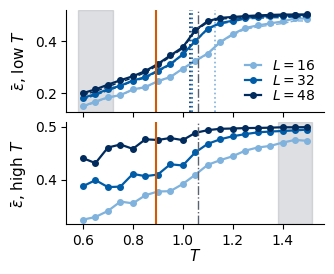

In [10]:
experiment("spins", "low")
experiment("spins", "high", seeds=(0,))

def curve(rep, region, L):                                       # seed-averaged per-snapshot errors (nT, 96)
    return np.mean([ERR[(rep, region, L, s)] for s in SEEDS if (rep, region, L, s) in ERR], 0)

def eval_theta(L):
    return DS[L]["theta"][:, np.isin(DS[L]["chain"], EVAL_CHAINS)]  # (nT, 96, L, L)

BASE = {}                                                         # baselines per snapshot, (nT, 96)
for L in L_LIST:
    th = eval_theta(L)
    m2 = np.cos(th).mean((-2, -1)) ** 2 + np.sin(th).mean((-2, -1)) ** 2
    w = np.asarray(to_vortices(jnp.asarray(th)))[..., 0]
    b = np.asarray(to_bonds(jnp.asarray(th)))
    BASE[("spins", L)] = (1 - m2) / 2
    BASE[("vortices", L)] = (w**2).mean((-2, -1))
    BASE[("bonds", L)] = b.var(axis=(-3, -2)).mean(-1)            # spatial variance of each bond channel, averaged over channels

T_AE = {}
for L in L_LIST:
    e = curve("spins", "low", L)
    T_AE[("spins", L)] = bootstrap_steepest(e, EVAL_CHAIN_IDX)
    seeds = [steepest(T_GRID, ERR[("spins", "low", L, s)].mean(1)) for s in SEEDS]
    r = np.corrcoef(e.mean(1), BASE[("spins", L)].mean(1))[0, 1]
    print(f"L = {L}: T_AE = {T_AE[('spins', L)][0]:.3f} +- {T_AE[('spins', L)][1]:.3f}  (seeds separately: "
          f"{', '.join(f'{t:.3f}' for t in seeds)});  correlation of the error curve with (1 - |m|^2)/2: {r:.4f}")
    NUMBERS[f"corr_spins_base_L{L}"] = round(float(r), 4)
hi = {L: curve("spins", "high", L).mean(1) for L in L_LIST}
for L in L_LIST:
    print(f"trained on high T, L = {L}: error from {hi[L].min():.4f} to {hi[L].max():.4f}  (relative range {(hi[L].max() - hi[L].min()) / hi[L].max():.3f})")
    NUMBERS[f"high_rel_range_L{L}"] = round(float((hi[L].max() - hi[L].min()) / hi[L].max()), 3)

fig, ax = plt.subplots(2, 1, figsize=(3.2, 2.6), sharex=True)
for L in L_LIST:
    ax[0].plot(T_GRID, curve("spins", "low", L).mean(1), "o-", color=L_COLORS[L], label=f"$L={L}$")
    ax[0].plot(T_GRID, BASE[("spins", L)].mean(1), "--", lw=1, color=L_COLORS[L])
    ax[0].axvline(T_AE[("spins", L)][0], color=L_COLORS[L], ls=":", lw=1.2)
    ax[1].plot(T_GRID, hi[L], "o-", color=L_COLORS[L], label=f"$L={L}$")
for a, reg, lab in zip(ax, ["low", "high"], [r"$\bar\varepsilon$, low $T$", r"$\bar\varepsilon$, high $T$"]):
    a.axvspan(T_GRID[REGIONS[reg]].min() - 0.02, T_GRID[REGIONS[reg]].max() + 0.02, color=UJGray, alpha=0.2)
    a.axvline(T_BKT_LIT, color=DSOrange, lw=1.5); a.axvline(T_CMAX[48], color=UJGray, lw=1, ls="-.")
    a.set_ylabel(lab)
ax[1].set_xlabel("$T$", labelpad=0)
ax[0].legend(frameon=False, loc="lower right", borderpad=0.1, labelspacing=0.1, handlelength=1.2)
fig.tight_layout(pad=0.2, h_pad=0.3); savefig(fig, "gen_xy_ml_ae_spins.png"); plt.show()
NUMBERS.update(**{f"T_ae_spins_L{L}": round(T_AE[("spins", L)][0], 3) for L in L_LIST},
               **{f"T_ae_spins_err_L{L}": round(T_AE[("spins", L)][1], 3) for L in L_LIST})

In the upper panel (orange line: $T_{\rm BKT}$; dash-dotted: the specific-heat maximum for $L=48$; shaded: training temperatures) the error
of the autoencoder trained at low temperature rises from the training level to the value $\approx1/2$ of a snapshot with no
magnetisation, and it lies close to the dashed baseline $\langle(1-|\boldsymbol m|^2)/2\rangle$ of the same size (correlations printed
above). With four latent numbers and random rotations in training, the most useful thing the network can store is the direction and
length of $\boldsymbol m$; the spin waves and vortices are left unreconstructed. Its anomaly score is therefore a function of the
magnetisation, and $T_{\rm AE}(L)$ (dotted lines) inherits the behaviour of $\langle|\mathbf w|\rangle$ from Section 3: above $T_{\rm BKT}$ for every
size and drifting downward with $L$. Beach, Golubeva and Melko (2018) observed the same for a supervised convolutional network: on raw
spins it learns the magnetisation.

Trained at the high-temperature end (lower panel), the network learns little more than the mean: its error on its own training
temperatures is close to $1/2$, the error of a snapshot without magnetisation. The low-temperature snapshots are then reconstructed
**better** than the training data, not worse, because the smooth, magnetised low-temperature configurations are easier to approximate
with the few uniform patterns the network has learned. The anomaly score has the wrong sign for detecting the ordered side, and the
difference between the two ends shrinks with the lattice size (the relative range of $\bar\varepsilon$ printed above falls from about
0.32 for $L=16$ to 0.14 for $L=48$). This is the same lesson as the paramagnetic training region in Labs 019 and 020: train on the
structured, well-understood phase.

### 4.3 Vortex maps and bond energies

Now the same network, the same training temperatures, the same split, but the input is the vortex map or the bond-energy map. The
baselines that interpret the errors are again the simplest reconstructions. For the vortex map, a network that outputs an empty map
($\hat w_r=0$) makes the error $\frac1N\sum_rw_r^2$, essentially the vortex density $n_v$ (exactly so when all winding numbers are $\pm1$).
For the bond map, a network that outputs the uniform map with the mean bond energy of the snapshot makes the error equal to the spatial
variance of the bond energies, averaged over the two channels.

vortices trained on low  T, L = 16: final training loss 0.0003, held-out error at the training T 0.0006, at T = 1.50: 0.1542  (5 s)


vortices trained on low  T, L = 32: final training loss 0.0001, held-out error at the training T 0.0005, at T = 1.50: 0.1491  (9 s)


vortices trained on low  T, L = 48: final training loss 0.0003, held-out error at the training T 0.0005, at T = 1.50: 0.1434  (14 s)


bonds    trained on low  T, L = 16: final training loss 0.0588, held-out error at the training T 0.0617, at T = 1.50: 0.4109  (5 s)


bonds    trained on low  T, L = 32: final training loss 0.0620, held-out error at the training T 0.0623, at T = 1.50: 0.4392  (9 s)


bonds    trained on low  T, L = 48: final training loss 0.0636, held-out error at the training T 0.0637, at T = 1.50: 0.4834  (16 s)
vortices L = 16: T_AE = 1.199 +- 0.042  (seeds: 1.200, 1.198);  correlation with the baseline: 0.9998
vortices L = 32: T_AE = 1.171 +- 0.058  (seeds: 1.167, 1.175);  correlation with the baseline: 1.0000
vortices L = 48: T_AE = 1.170 +- 0.036  (seeds: 1.170, 1.170);  correlation with the baseline: 1.0000
bonds    L = 16: T_AE = 1.146 +- 0.059  (seeds: 1.143, 1.150);  correlation with the baseline: 0.9998


bonds    L = 32: T_AE = 1.047 +- 0.047  (seeds: 1.046, 1.048);  correlation with the baseline: 0.9990
bonds    L = 48: T_AE = 1.041 +- 0.022  (seeds: 1.048, 1.031);  correlation with the baseline: 0.9966
L = 16: steepest rise of <n_v>: 1.154   steepest rise of u (= maximum of du/dT): 1.127   specific-heat maximum: 1.117
L = 32: steepest rise of <n_v>: 1.120   steepest rise of u (= maximum of du/dT): 1.072   specific-heat maximum: 1.067
L = 48: steepest rise of <n_v>: 1.104   steepest rise of u (= maximum of du/dT): 1.055   specific-heat maximum: 1.060


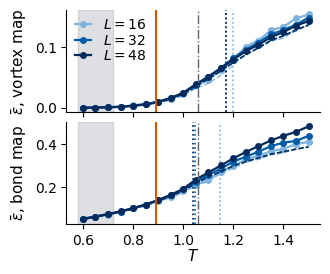

In [11]:
experiment("vortices", "low")
experiment("bonds", "low")
for rep in ["vortices", "bonds"]:
    for L in L_LIST:
        e = curve(rep, "low", L)
        T_AE[(rep, L)] = bootstrap_steepest(e, EVAL_CHAIN_IDX)
        r = np.corrcoef(e.mean(1), BASE[(rep, L)].mean(1))[0, 1]
        seeds = [steepest(T_GRID, ERR[(rep, "low", L, s)].mean(1)) for s in SEEDS]
        print(f"{rep:8s} L = {L}: T_AE = {T_AE[(rep, L)][0]:.3f} +- {T_AE[(rep, L)][1]:.3f}  (seeds: "
              f"{', '.join(f'{t:.3f}' for t in seeds)});  correlation with the baseline: {r:.4f}")
        NUMBERS[f"T_ae_{rep}_L{L}"] = round(T_AE[(rep, L)][0], 3); NUMBERS[f"T_ae_{rep}_err_L{L}"] = round(T_AE[(rep, L)][1], 3)
        NUMBERS[f"corr_{rep}_base_L{L}"] = round(float(r), 4)
# the same steepest-rise estimator applied to the known observables
T_NV = {L: steepest(T_GRID, REF[L]["nv"]) for L in L_LIST}
T_U = {L: steepest(T_GRID, REF[L]["u"]) for L in L_LIST}
for L in L_LIST:
    print(f"L = {L}: steepest rise of <n_v>: {T_NV[L]:.3f}   steepest rise of u (= maximum of du/dT): {T_U[L]:.3f}   "
          f"specific-heat maximum: {T_CMAX[L]:.3f}")
NUMBERS.update(**{f"T_nv_L{L}": round(T_NV[L], 3) for L in L_LIST}, **{f"T_u_L{L}": round(T_U[L], 3) for L in L_LIST})

fig, ax = plt.subplots(2, 1, figsize=(3.2, 2.6), sharex=True)
ylab = {"vortices": r"$\bar\varepsilon$, vortex map", "bonds": r"$\bar\varepsilon$, bond map"}
for a, rep in zip(ax, ["vortices", "bonds"]):
    for L in L_LIST:
        a.plot(T_GRID, curve(rep, "low", L).mean(1), "o-", color=L_COLORS[L], label=f"$L={L}$")
        a.plot(T_GRID, BASE[(rep, L)].mean(1), "--", lw=1, color=L_COLORS[L])
        a.axvline(T_AE[(rep, L)][0], color=L_COLORS[L], ls=":", lw=1.2)
    a.axvspan(0.58, 0.72, color=UJGray, alpha=0.2)
    a.axvline(T_BKT_LIT, color=DSOrange, lw=1.5); a.axvline(T_CMAX[48], color=UJGray, lw=1, ls="-.")
    a.set_ylabel(ylab[rep])
ax[1].set_xlabel("$T$", labelpad=0)
ax[0].legend(frameon=False, loc="upper left", borderpad=0.1, labelspacing=0.1, handlelength=1.2)
fig.tight_layout(pad=0.2, h_pad=0.3); savefig(fig, "gen_xy_ml_ae_inputs.png"); plt.show()

The representation decides what the autoencoder measures. On the **vortex map** the network trained at low temperature has seen almost
only empty maps, learns to output (nearly) zero, and its error coincides with the vortex-density baseline: the anomaly score is $n_v$.
The vortex density is smooth and nearly independent of $L$ (Lab 030, Section 4.4), so $T_{\rm AE}=1.20,\,1.17,\,1.17$ for $L=16,32,48$
agree within their bootstrap errors of about $0.04$–$0.06$ and with the steepest rise of $\langle n_v\rangle$ itself ($1.10$–$1.15$):
far above $T_{\rm BKT}$ and above the specific-heat maximum. The rotation-invariant, physics-informed input removed the
finite-size magnetisation, but the detector now counts defects instead of asking whether they are bound in pairs. On the **bond map** the
error follows the spatial fluctuations of the local energy, and its steepest rise ($1.15,\,1.05,\,1.04$) lies within its errors on the
steepest rise of the energy, i.e. on the specific-heat maximum ($1.12,\,1.07,\,1.06$), and moves with it between $L=16$ and $L=32$:
again above $T_{\rm BKT}$.

### 4.4 Network capacity and finite-size extrapolation

Two objections can be raised against the negative result of Sections 4.2 and 4.3. The first is technical: perhaps the network is too
small, or trained too briefly, to see anything beyond the magnetisation or the vortex density, and a larger or better-trained model would
move its temperature towards $T_{\rm BKT}$. The second is physical: on every finite lattice a BKT transition is rounded into a crossover,
and even the stiffness crossings $T^*(L)$ of Lab 030 lie above $T_{\rm BKT}$; they reach $T_{\rm BKT}$ only after an extrapolation in
$L$. Both objections can be tested.

For the first, we vary one property of the autoencoder at a time around the baseline used so far (4 latent numbers, 16 and 32 filters,
40 epochs) for $L=32$: the latent size ($2, 8, 16$), the width (all filter numbers multiplied by 2 or 4), and the training time (120
epochs instead of 40). Each variant of the raw-spin autoencoder is trained with the two seeds of Section 4.2; for the vortex autoencoder
we test the three largest changes with one seed each. For every variant we record the final training loss, the held-out error at the
training temperatures, and the temperature estimate $T_{\rm AE}$ with its bootstrap error. If the network were limited by capacity or
training, the loss would fall and $T_{\rm AE}$ would move; the criterion is whether it moves by more than its bootstrap error.


In [12]:
VARIANTS = {"baseline": {}, "latent 2": dict(latent=2), "latent 8": dict(latent=8), "latent 16": dict(latent=16),
            "width x2": dict(width=2), "width x4": dict(width=4), "epochs x3": dict(epochs=3 * EPOCHS)}
SWEEP = {}
L = 32
for rep, names, seeds in [("spins", list(VARIANTS), SEEDS), ("vortices", ["baseline", "latent 16", "width x4", "epochs x3"], (0,))]:
    for name in names:
        t0 = time.time()
        if name == "baseline":                                         # reuse the models of Sections 4.2 and 4.3
            errs = [ERR[(rep, "low", L, s)] for s in seeds]; losses = [LOSS[(rep, "low", L, s)] for s in seeds]
        else:
            out = [run_ae(L, rep, "low", s, **VARIANTS[name]) for s in seeds]
            errs = [o[0] for o in out]; losses = [o[1] for o in out]
        e = np.mean(errs, 0)
        T_est, dT_est = bootstrap_steepest(e, EVAL_CHAIN_IDX)
        SWEEP[(rep, name)] = dict(T=T_est, dT=dT_est, loss=float(np.mean(losses)), e_train=float(e[REGIONS["low"]].mean()))
        print(f"{rep:8s} {name:10s}: final training loss {np.mean(losses):.4f}, held-out error at T <= 0.70 "
              f"{e[REGIONS['low']].mean():.4f},  T_AE = {T_est:.3f} +- {dT_est:.3f}   ({time.time() - t0:.0f} s)")
for rep in ["spins", "vortices"]:
    b = SWEEP[(rep, "baseline")]
    shifts = [abs(v["T"] - b["T"]) / np.hypot(v["dT"], b["dT"]) for (r, n), v in SWEEP.items() if r == rep and n != "baseline"]
    print(f"{rep}: largest shift of T_AE from the baseline, in units of the combined bootstrap error: {max(shifts):.2f}")
    NUMBERS[f"sweep_max_shift_sigma_{rep}"] = round(float(max(shifts)), 2)
NUMBERS["sweep"] = {f"{r}: {n}": {k: round(v, 4) for k, v in d.items()} for (r, n), d in SWEEP.items()}


spins    baseline  : final training loss 0.1939, held-out error at T <= 0.70 0.1966,  T_AE = 1.038 +- 0.007   (0 s)


spins    latent 2  : final training loss 0.2089, held-out error at T <= 0.70 0.2149,  T_AE = 1.037 +- 0.007   (10 s)


spins    latent 8  : final training loss 0.1866, held-out error at T <= 0.70 0.1888,  T_AE = 1.037 +- 0.008   (10 s)


spins    latent 16 : final training loss 0.1732, held-out error at T <= 0.70 0.1761,  T_AE = 1.039 +- 0.008   (11 s)


spins    width x2  : final training loss 0.1923, held-out error at T <= 0.70 0.1938,  T_AE = 1.036 +- 0.007   (24 s)


spins    width x4  : final training loss 0.1887, held-out error at T <= 0.70 0.1903,  T_AE = 1.038 +- 0.007   (50 s)


spins    epochs x3 : final training loss 0.1843, held-out error at T <= 0.70 0.1873,  T_AE = 1.038 +- 0.007   (23 s)
vortices baseline  : final training loss 0.0003, held-out error at T <= 0.70 0.0005,  T_AE = 1.167 +- 0.116   (0 s)


vortices latent 16 : final training loss 0.0001, held-out error at T <= 0.70 0.0005,  T_AE = 1.163 +- 0.040   (6 s)


vortices width x4  : final training loss 0.0001, held-out error at T <= 0.70 0.0005,  T_AE = 1.179 +- 0.045   (26 s)


vortices epochs x3 : final training loss 0.0004, held-out error at T <= 0.70 0.0005,  T_AE = 1.154 +- 0.093   (11 s)
spins: largest shift of T_AE from the baseline, in units of the combined bootstrap error: 0.14
vortices: largest shift of T_AE from the baseline, in units of the combined bootstrap error: 0.10


For the second objection we treat the PCA and autoencoder temperatures like the stiffness crossings of Lab 030. Above $T_{\rm BKT}$ the
correlation length grows as $\xi\propto\exp\!\big(b'/\sqrt{T-T_{\rm BKT}}\big)$; a finite-size crossover sits where $\xi\approx L$, which gives
$$
T(L)=T_\infty+\frac{b}{(\ln L)^2},
$$
a straight line in the variable $x=1/(\ln L)^2$, with $T_\infty=T_{\rm BKT}$ if the crossover is controlled by the BKT correlation length.
We fit this form, weighted with the bootstrap errors, to the PCA temperatures and to the raw-spin autoencoder temperatures. With three sizes
and two parameters there is one degree of freedom, so a good fit is not a test of the form. A sharper question has a definite answer: fixing
$T_\infty=0.8929$ and fitting only $b$ leaves two degrees of freedom. The goodness of a fit is measured by
$\chi^2=\sum_L\big(T(L)-T_{\rm fit}(L)\big)^2/\sigma_L^2$, the squared deviations in units of the errors $\sigma_L$; for a correct model it is
of the order of the number of degrees of freedom, and the $p$-value, the probability of a $\chi^2$ at least as large if the model is
correct, says whether the data are consistent with a crossover that extrapolates to $T_{\rm BKT}$ (a $p$-value below a few per cent would
reject it). For comparison we apply the same analysis to the stiffness crossings
(with jackknife errors over the chains, as in Lab 030: the crossing is recomputed 24 times, each time leaving one chain out, and
the spread of these values gives the error) and, as a control without errors (unweighted), to the specific-heat maximum, which
is not expected to approach $T_{\rm BKT}$.


stiffness crossing    : T_inf = 0.897 +- 0.003  (chi2 = 0.14, 1 dof);   T_inf fixed at 0.8929: chi2 = 1.92 (2 dof), p = 0.38
PCA                   : T_inf = 0.932 +- 0.020  (chi2 = 0.25, 1 dof);   T_inf fixed at 0.8929: chi2 = 4.22 (2 dof), p = 0.12
AE on spins           : T_inf = 0.952 +- 0.036  (chi2 = 1.50, 1 dof);   T_inf fixed at 0.8929: chi2 = 4.15 (2 dof), p = 0.13
specific-heat maximum : T_inf = 0.995 (unweighted, no errors)


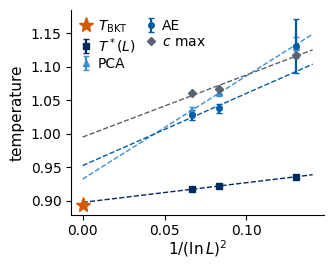

In [13]:
from scipy.optimize import curve_fit
from scipy.stats import chi2 as chi2_dist

def jackknife_crossing(L):
    # stiffness crossing T*(L) and its jackknife error over the 24 chains (Lab 030, Section 5.3)
    cm = DS[L]["chain_moments"]; n = cm.shape[1]; N = L * L; beta = 1.0 / T_GRID
    ups = lambda v: (v[:, MOM.index("C")] - beta * v[:, MOM.index("S2")]) / (2 * N)
    loo = np.array([crossing(T_GRID, ups((cm.sum(1) - cm[:, j]) / (n - 1))) for j in range(n)])
    return crossing(T_GRID, ups(cm.mean(1))), float(np.sqrt((n - 1) / n * ((loo - loo.mean()) ** 2).sum()))

xL = 1.0 / np.log(np.array(L_LIST, float)) ** 2

def bkt_fits(T, dT):
    # free fit T = T_inf + b x (weighted) and fit with T_inf fixed at T_BKT; returns a dict of results
    line = lambda x, T0, b: T0 + b * x
    if dT is None:
        p = np.polyfit(xL, T, 1); return dict(T_inf=p[1], dT_inf=np.nan, b=p[0], chi2=np.nan, chi2_fix=np.nan, p_fix=np.nan)
    p, cov = curve_fit(line, xL, T, sigma=dT, absolute_sigma=True, p0=(0.9, 1.0))
    w = 1 / dT**2
    b_fix = np.sum(w * xL * (T - T_BKT_LIT)) / np.sum(w * xL**2)
    chi2_fix = float(np.sum(w * (T - T_BKT_LIT - b_fix * xL) ** 2))
    return dict(T_inf=p[0], dT_inf=float(np.sqrt(cov[0, 0])), b=p[1], chi2=float(np.sum(w * (T - line(xL, *p)) ** 2)),
                b_fix=b_fix, chi2_fix=chi2_fix, p_fix=float(chi2_dist.sf(chi2_fix, 2)))

UPS_JK = {L: jackknife_crossing(L) for L in L_LIST}
SERIES = {"stiffness crossing": ([UPS_JK[L][0] for L in L_LIST], [UPS_JK[L][1] for L in L_LIST]),
          "PCA": ([T_PCA[L][0] for L in L_LIST], [T_PCA[L][1] for L in L_LIST]),
          "AE on spins": ([T_AE[("spins", L)][0] for L in L_LIST], [T_AE[("spins", L)][1] for L in L_LIST]),
          "specific-heat maximum": ([T_CMAX[L] for L in L_LIST], None)}
FITS = {}
for name, (T_, dT_) in SERIES.items():
    FITS[name] = f = bkt_fits(np.array(T_), None if dT_ is None else np.array(dT_))
    if dT_ is None:
        print(f"{name:22s}: T_inf = {f['T_inf']:.3f} (unweighted, no errors)")
    else:
        print(f"{name:22s}: T_inf = {f['T_inf']:.3f} +- {f['dT_inf']:.3f}  (chi2 = {f['chi2']:.2f}, 1 dof);   "
              f"T_inf fixed at {T_BKT_LIT:.4f}: chi2 = {f['chi2_fix']:.2f} (2 dof), p = {f['p_fix']:.2f}")
NUMBERS["extrapolation"] = {k: {kk: round(float(vv), 4) for kk, vv in v.items()} for k, v in FITS.items()}

fig, ax = plt.subplots(figsize=(3.2, 2.55))
xf = np.linspace(0, xL.max() * 1.08, 50)
for name, lab, col, mk in [("stiffness crossing", r"$T^*(L)$", UJNavy, "s"), ("PCA", "PCA", "#3E8FD0", "^"),
                           ("AE on spins", "AE", UJBlue, "o"), ("specific-heat maximum", r"$c$ max", UJGray, "D")]:
    T_, dT_ = SERIES[name]; f = FITS[name]
    ax.errorbar(xL, T_, None if dT_ is None else dT_, fmt=mk, color=col, capsize=2, label=lab)
    ax.plot(xf, f["T_inf"] + f["b"] * xf, "--", color=col, lw=1)
ax.plot(0, T_BKT_LIT, "*", color=DSOrange, ms=11, label=r"$T_{\rm BKT}$")
ax.set_xlabel(r"$1/(\ln L)^2$", labelpad=0); ax.set_ylabel("temperature")
ax.legend(frameon=False, loc="upper left", ncol=2, borderpad=0.1, labelspacing=0.1, columnspacing=0.6, handlelength=1.0,
          handletextpad=0.3)
fig.tight_layout(pad=0.2); savefig(fig, "gen_xy_ml_fss.png"); plt.show()


The first objection is answered by the table printed above. For the raw-spin autoencoder at $L=32$ the final training loss changes between
variants (from $0.209$ with 2 latent numbers to $0.173$ with 16, against $0.194$ for the baseline), so the variants are genuinely
different networks, yet every estimate lies between $1.036$ and $1.039$, with bootstrap errors of $0.007$–$0.008$: the largest shift from the
baseline is $0.14$ times the combined error. The vortex autoencoder behaves the same way (largest shift $0.10$ times the error). Network
capacity and training time are therefore ruled out as the reason why the temperatures lie above $T_{\rm BKT}$: a larger or longer-trained
network reconstructs the snapshots slightly better but measures the same thing.

The second objection is more interesting. The figure shows the temperatures against $1/(\ln L)^2$ with the straight-line fits (the star marks $T_{\rm BKT}$ at $L\to\infty$).
The stiffness crossings extrapolate to $0.897\pm0.003$, and fixing $T_\infty=T_{\rm BKT}$ gives $\chi^2=1.92$ for two degrees of freedom
($p=0.38$), as in Lab 030. The PCA temperatures extrapolate to $T_\infty=0.932\pm0.020$ and the raw-spin autoencoder temperatures to
$0.952\pm0.036$, that is $2.0$ and $1.6$ standard errors above $T_{\rm BKT}$; with $T_\infty$ fixed at $0.8929$ the fits give $\chi^2=4.22$
($p=0.12$) and $\chi^2=4.15$ ($p=0.13$). The magnetisation crossover is therefore **consistent** with a BKT-type drift towards
$T_{\rm BKT}$, which is what one expects physically: the magnetisation of the finite lattice drops where the correlation length reaches
$L$, and the correlation length diverges at $T_{\rm BKT}$. The same extrapolation applied to the specific-heat maximum gives $0.995$, well
above $T_{\rm BKT}$, so the fitted form does not pull every set of three numbers onto $T_{\rm BKT}$.

Two caveats keep this from being a measurement of $T_{\rm BKT}$ by machine learning. Three sizes and two parameters leave one degree of
freedom, and the $p$-values of the fixed fits only say that $T_{\rm BKT}$ is not excluded; the free fits are equally compatible with a
limit near $0.93$–$0.95$. And the extrapolation form $b/(\ln L)^2$ is not produced by the method: it comes from the Kosterlitz
renormalisation-group result for the correlation length, i.e. from knowing beforehand that the transition is of the BKT type.

<hr/>
## 5. Summary

We collect every temperature produced in this notebook next to the reference values, for the three lattice sizes. The figure shows them
against $L$: the stiffness crossings $T^*(L)$ and the specific-heat maxima from Section 1, the steepest fall of the PCA magnetisation, the
steepest rise of the three autoencoder errors, and the literature value $T_{\rm BKT}=0.8929$.

                                          L = 16            L = 32            L = 48
stiffness crossing T*(L)            0.936             0.921             0.917       
specific-heat maximum               1.117             1.067             1.060       
PCA, steepest fall of <|w|>         1.129 +-0.015      1.062 +-0.006      1.033 +-0.006
AE on spins                         1.130 +-0.040      1.038 +-0.007      1.028 +-0.007
AE on bond energies                 1.146 +-0.059      1.047 +-0.047      1.041 +-0.022
AE on vortex maps                   1.199 +-0.042      1.171 +-0.058      1.170 +-0.036
T_BKT (Hasenbusch 2005)            0.8929


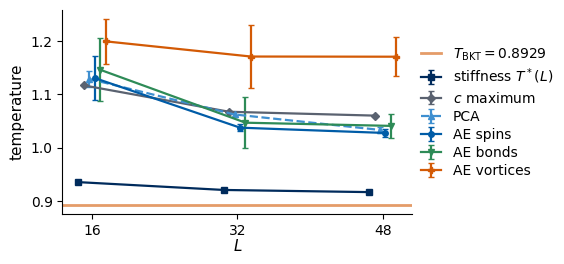

In [14]:
rows = [("stiffness crossing T*(L)", {L: (T_UPS[L], np.nan) for L in L_LIST}),
        ("specific-heat maximum", {L: (T_CMAX[L], np.nan) for L in L_LIST}),
        ("PCA, steepest fall of <|w|>", T_PCA),
        ("AE on spins", {L: T_AE[("spins", L)] for L in L_LIST}),
        ("AE on bond energies", {L: T_AE[("bonds", L)] for L in L_LIST}),
        ("AE on vortex maps", {L: T_AE[("vortices", L)] for L in L_LIST})]
print(f"{'':30s}" + "".join(f"{'L = ' + str(L):>18s}" for L in L_LIST))
for name, vals in rows:
    print(f"{name:30s}" + "".join(f"{vals[L][0]:>11.3f}" + (f" +-{vals[L][1]:.3f}" if np.isfinite(vals[L][1]) else " " * 7) for L in L_LIST))
print(f"{'T_BKT (Hasenbusch 2005)':30s}{T_BKT_LIT:>11.4f}")

styles = {"stiffness crossing T*(L)": ("s-", UJNavy, r"stiffness $T^*(L)$"), "specific-heat maximum": ("D-", UJGray, r"$c$ maximum"),
          "PCA, steepest fall of <|w|>": ("^--", "#3E8FD0", "PCA"), "AE on spins": ("o-", UJBlue, "AE spins"),
          "AE on bond energies": ("v-", Green, "AE bonds"), "AE on vortex maps": ("P-", DSOrange, "AE vortices")}
fig, ax = plt.subplots(figsize=(5.5, 2.5))
for k, (name, vals) in enumerate(rows):
    fmt, col, lab = styles[name]
    x = np.array(L_LIST) + (k - 2.5) * 0.6
    ax.errorbar(x, [vals[L][0] for L in L_LIST], [0 if not np.isfinite(vals[L][1]) else vals[L][1] for L in L_LIST],
                fmt=fmt, color=col, capsize=2, label=lab)
ax.axhline(T_BKT_LIT, color=DSOrange, lw=2, alpha=0.6, label=r"$T_{\rm BKT}=0.8929$")
ax.set_xticks(L_LIST); ax.set_xlabel("$L$", labelpad=0); ax.set_ylabel("temperature")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5), borderpad=0.1, labelspacing=0.3, handlelength=1.5)
fig.tight_layout(pad=0.2); savefig(fig, "gen_xy_ml_summary.png"); plt.show()

All three autoencoders and PCA return a temperature above $T_{\rm BKT}$ on every lattice we have: for $L=48$ between $1.03$ and $1.17$,
that is $0.14$ to $0.28$ above $T_{\rm BKT}=0.893$ and well above the stiffness crossing $T^*(48)=0.917$. None of them finds the BKT
transition; each finds the quantity its input makes easy to see. On raw spins, both PCA and the autoencoder measure the magnetisation of
the finite lattice. Its steepest fall is a finite-size crossover; it drifts down with $L$ (from $1.13$ at $L=16$ to $1.03$ at $L=48$), and
for $L=32$ and $48$ it lies just below the specific-heat maximum, not near the stiffness crossings. It is not a property of the
thermodynamic limit, in which the magnetisation is zero at every temperature. Section 4.4 showed that this is not a matter of network size
or training, and that the drift of this crossover with $L$ is consistent with an approach to $T_{\rm BKT}$ when it is extrapolated with
the BKT form, an extrapolation that needs the physics as input and that three lattice sizes cannot make precise. On the vortex map the autoencoder measures the vortex density, whose rise is smooth, $L$-independent and well
above both $T_{\rm BKT}$ and the specific-heat maximum. On the bond map it measures energy fluctuations and lands near the specific-heat
maximum, the smooth non-critical feature of Lab 030, Section 7.

The comparison with Labs 019 and 020 is instructive. There the order parameter was linear in the spins, and the unsupervised signal moved
towards the true $T_c$ as $L$ grew. Here the defining property of the low-temperature phase is the binding of vortices into pairs and the
resulting spin stiffness, a response to a twist that no single map of the snapshot displays as a simple pattern. A detector built for
"is this snapshot like the training data" picks up whatever changes most, and in the XY model that is the magnetisation, the vortex density
or the energy, all of which change smoothly through $T_{\rm BKT}$. Only the knowledge of the physics (Lab 030) tells us that the
temperatures in the table are a finite-size crossover and two smooth features, and that $T_{\rm BKT}$ has to be obtained from the
stiffness.

## Exercises

1. Replace the vortex map by a map of **free** vortices: keep $w_r$ only if no plaquette of opposite sign lies within a distance $d$
   (try $d=1,2$). Train the autoencoder of Section 4.3 on it. Does the steepest rise move towards $T_{\rm BKT}$?
2. Apply the extrapolation of Section 4.4 to the autoencoders on bond energies and on vortex maps. Which limits do you obtain, and
   what do they mean physically?
3. Replace the steepest-rise estimator by the temperature at which $\bar\varepsilon(T)$ is halfway between its value at $T=0.60$ and at
   $T=1.50$. Do $T_{\rm AE}(L)$ and its extrapolation change?
4. Train the vortex autoencoder at the high-temperature end. Explain the shape of $\bar\varepsilon(T)$ from the vortex density.

<hr/>
## References

* M. J. S. Beach, A. Golubeva, R. G. Melko, *Machine learning vortices at the Kosterlitz-Thouless transition*, Phys. Rev. B **97**, 045207 (2018), [doi:10.1103/PhysRevB.97.045207](https://doi.org/10.1103/PhysRevB.97.045207), [arXiv:1710.09842](https://arxiv.org/abs/1710.09842)
* W. Hu, R. R. P. Singh, R. T. Scalettar, *Discovering phases, phase transitions, and crossovers through unsupervised machine learning: A critical examination*, Phys. Rev. E **95**, 062122 (2017), [doi:10.1103/PhysRevE.95.062122](https://doi.org/10.1103/PhysRevE.95.062122), [arXiv:1704.00080](https://arxiv.org/abs/1704.00080)
* C. Wang, H. Zhai, *Machine learning of frustrated classical spin models. I. Principal component analysis*, Phys. Rev. B **96**, 144432 (2017), [doi:10.1103/PhysRevB.96.144432](https://doi.org/10.1103/PhysRevB.96.144432), [arXiv:1706.07977](https://arxiv.org/abs/1706.07977)
* K. Kottmann, P. Huembeli, M. Lewenstein, A. Acín, *Unsupervised phase discovery with deep anomaly detection*, Phys. Rev. Lett. **125**, 170603 (2020), [doi:10.1103/PhysRevLett.125.170603](https://doi.org/10.1103/PhysRevLett.125.170603)
* M. Hasenbusch, *The two-dimensional XY model at the transition temperature: a high-precision Monte Carlo study*, J. Phys. A **38**, 5869 (2005), [doi:10.1088/0305-4470/38/26/003](https://doi.org/10.1088/0305-4470/38/26/003)
* Physics of the model and the data set: Lab 030 of this course, with the original references on the BKT transition.